# Retinal Image Validation Using MobileNetV2

## Objective

Develop a lightweight binary classification model to
distinguish retinal fundus images from non-retinal images
before diabetic retinopathy severity assessment.

## Architecture

MobileNetV2 with ImageNet pretrained weights and
a custom binary classification head.

## Class Mapping

0 - Non-Retinal Image
1 - Retinal Fundus Image

In [3]:
import os
import sys
import random
from pathlib import Path

import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

SEED = 42

tf.keras.utils.set_random_seed(SEED)

print("TensorFlow:", tf.__version__)
print("Libraries imported successfully.")

TensorFlow: 2.21.0
Libraries imported successfully.


In [4]:
PROJECT_ROOT = next(
    p for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "ml-model" / "dataset").exists()
)

ML_ROOT = PROJECT_ROOT / "ml-model"

VALIDATOR_DIR = (
    ML_ROOT / "dataset" / "retinal_validation"
)

METADATA_DIR = VALIDATOR_DIR / "metadata"

HARD_NEGATIVE_DIR = VALIDATOR_DIR / "hard_negatives"

MODEL_DIR = ML_ROOT / "models"

SAVE_DIR = ML_ROOT / "saved_models"

SAVE_DIR.mkdir(
    parents=True,
    exist_ok=True
)

MODEL_PATH = SAVE_DIR / "retinal_validator.keras"

IMAGE_SIZE = (224, 224)

BATCH_SIZE = 16

EPOCHS = 10

LEARNING_RATE = 0.001

print("Project Root:", PROJECT_ROOT)
print("Model Save Path:", MODEL_PATH)

Project Root: d:\AI-Powered-Diabetic-Retinopathy-System
Model Save Path: d:\AI-Powered-Diabetic-Retinopathy-System\ml-model\saved_models\retinal_validator.keras


In [5]:
def load_split(split_name):

    df = pd.read_csv(
        METADATA_DIR / f"{split_name}.csv"
    )

    # Resolve relative paths
    df["image_path"] = df["image_path"].apply(
        lambda p: str(PROJECT_ROOT / p)
    )

    # Include challenging negative examples
    hard_negative_path = (
        HARD_NEGATIVE_DIR / split_name
    )

    valid_extensions = {
        ".jpg", ".jpeg", ".png"
    }

    records = []

    if hard_negative_path.exists():

        for path in sorted(
            hard_negative_path.rglob("*")
        ):

            if (
                path.is_file()
                and path.suffix.lower()
                in valid_extensions
            ):

                records.append({
                    "image_path": str(path),
                    "label": 0,
                    "class_name": "non_retinal",
                    "source": "hard_negative"
                })

    if records:

        df = pd.concat(
            [df, pd.DataFrame(records)],
            ignore_index=True
        )

    assert df["image_path"].apply(
        os.path.isfile
    ).all()

    assert df["image_path"].is_unique

    return df.reset_index(drop=True)


train_df = load_split("train")

val_df = load_split("validation")

# Leave test data untouched until final evaluation.

print("Training Images:", len(train_df))
print("Validation Images:", len(val_df))

print("\nTraining Distribution:")

print(train_df["class_name"].value_counts())

print("\nValidation Distribution:")

print(val_df["class_name"].value_counts())

Training Images: 2800
Validation Images: 600

Training Distribution:
class_name
retinal        1400
non_retinal    1400
Name: count, dtype: int64

Validation Distribution:
class_name
retinal        300
non_retinal    300
Name: count, dtype: int64


In [6]:
def load_image(image_path, label):

    image = tf.io.read_file(image_path)

    image = tf.image.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize(
        image,
        IMAGE_SIZE
    )

    image = tf.cast(
        image,
        tf.float32
    )

    label = tf.cast(
        label,
        tf.float32
    )

    label = tf.reshape(
        label,
        [1]
    )

    return image, label

In [7]:
def create_validator_dataset(
    df,
    training=False
):

    image_paths = df["image_path"].tolist()

    labels = df["label"].to_numpy(
        dtype=np.float32
    )

    dataset = tf.data.Dataset.from_tensor_slices(
        (image_paths, labels)
    )

    if training:

        dataset = dataset.shuffle(
            buffer_size=len(df),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    dataset = dataset.map(
        load_image,
        num_parallel_calls=2
    )

    dataset = dataset.batch(
        BATCH_SIZE
    )

    dataset = dataset.prefetch(1)

    return dataset


train_dataset = create_validator_dataset(
    train_df,
    training=True
)

val_dataset = create_validator_dataset(
    val_df
)

print("Datasets created successfully.")

Datasets created successfully.


In [8]:
for images, labels in train_dataset.take(1):

    print("Image Batch Shape:", images.shape)

    print("Label Batch Shape:", labels.shape)

    print("Image Data Type:", images.dtype)

    print("Minimum Pixel Value:")

    print(tf.reduce_min(images).numpy())

    print("Maximum Pixel Value:")

    print(tf.reduce_max(images).numpy())

    print("Labels:", labels.numpy().flatten())

Image Batch Shape: (16, 224, 224, 3)
Label Batch Shape: (16, 1)
Image Data Type: <dtype: 'float32'>
Minimum Pixel Value:
0.0
Maximum Pixel Value:
255.0
Labels: [0. 0. 1. 1. 0. 0. 0. 0. 0. 1. 1. 1. 1. 0. 1. 1.]


In [9]:
if str(MODEL_DIR) not in sys.path:

    sys.path.insert(
        0,
        str(MODEL_DIR)
    )

from retinal_validator_model import (
    build_retinal_validator
)

model = build_retinal_validator(
    learning_rate=LEARNING_RATE
)

model.summary()

Model: "Retinal_Image_Validator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 224, 224, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling          │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_features (Dense)          │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ retinal_probability (Dense)     │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,081 (9.24 MB)

 Trainable params: 164,097 (641.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [10]:
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau,
    CSVLogger
)

callbacks = [

    ModelCheckpoint(
        filepath=str(MODEL_PATH),
        monitor="val_loss",
        save_best_only=True,
        mode="min",
        verbose=1
    ),

    EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1
    ),

    CSVLogger(
        str(
            SAVE_DIR
            / "retinal_validator_training.csv"
        )
    )
]

print("Training callbacks configured.")

Training callbacks configured.


In [11]:
history = model.fit(

    train_dataset,

    validation_data=val_dataset,

    epochs=EPOCHS,

    callbacks=callbacks,

    verbose=1
)

Epoch 1/10


d:\AI-Powered-Diabetic-Retinopathy-System\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


175/175 ━━━━━━━━━━━━━━━━━━━━ 0s 424ms/step - accuracy: 0.9975 - auc: 1.0000 - loss: 0.0055 - precision: 0.9971 - recall: 0.9979
Epoch 1: val_loss improved from None to 0.00001, saving model to d:\AI-Powered-Diabetic-Retinopathy-System\ml-model\saved_models\retinal_validator.keras

Epoch 1: finished saving model to d:\AI-Powered-Diabetic-Retinopathy-System\ml-model\saved_models\retinal_validator.keras
175/175 ━━━━━━━━━━━━━━━━━━━━ 97s 526ms/step - accuracy: 0.9975 - auc: 1.0000 - loss: 0.0055 - precision: 0.9971 - recall: 0.9979 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 1.1024e-05 - val_precision: 1.0000 - val_recall: 1.0000 - learning_rate: 0.0010
Epoch 2/10
175/175 ━━━━━━━━━━━━━━━━━━━━ 0s 428ms/step - accuracy: 1.0000 - auc: 1.0000 - loss: 1.7306e-05 - precision: 1.0000 - recall: 1.0000
Epoch 2: val_loss improved from 0.00001 to 0.00000, saving model to d:\AI-Powered-Diabetic-Retinopathy-System\ml-model\saved_models\retinal_validator.keras

Epoch 2: finished saving model to 

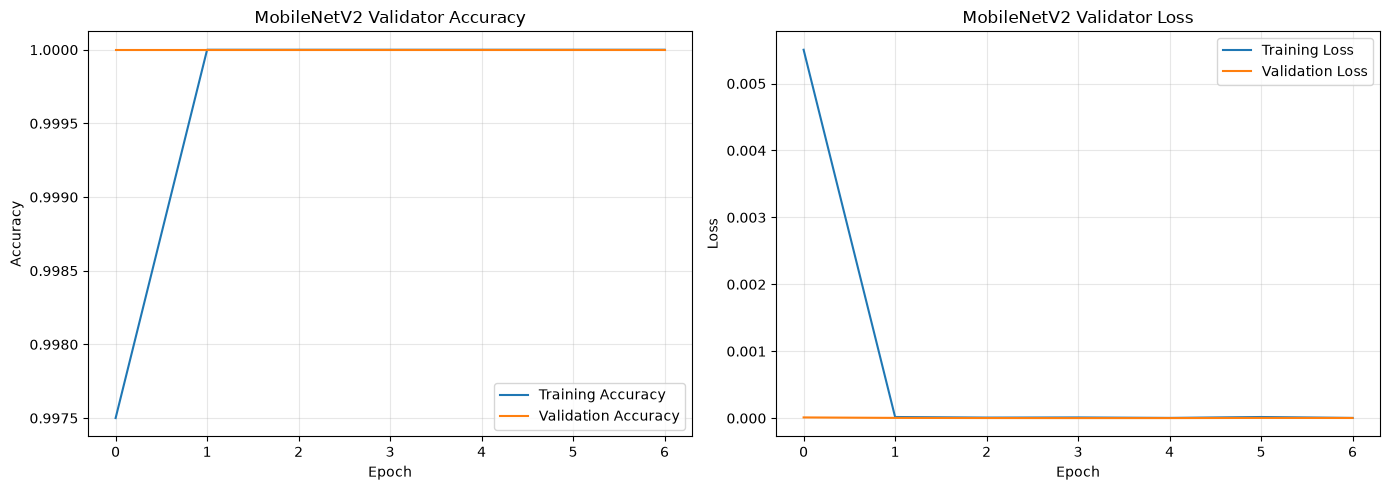

In [12]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5)
)

# Accuracy
axes[0].plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

axes[0].plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

axes[0].set_title(
    "MobileNetV2 Validator Accuracy"
)

axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Loss
axes[1].plot(
    history.history["loss"],
    label="Training Loss"
)

axes[1].plot(
    history.history["val_loss"],
    label="Validation Loss"
)

axes[1].set_title(
    "MobileNetV2 Validator Loss"
)

axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()

plt.show()

In [14]:
best_epoch = (
    np.argmin(
        history.history["val_loss"]
    ) + 1
)

print("=" * 60)
print("RETINAL VALIDATOR TRAINING SUMMARY")
print("=" * 60)

print("Best Epoch:", best_epoch)

for metric in [
    "loss",
    "accuracy",
    "precision",
    "recall",
    "auc"
]:

    value = history.history[
        f"val_{metric}"
    ][best_epoch - 1]

    print(
        f"Validation {metric}: {value:.4f}"
    )

print("\nTotal Parameters:")

print(model.count_params())

print("\nTrainable Parameters:")

print(
    sum(
        np.prod(weight.shape)
        for weight in model.trainable_weights
    )
)

print("\nModel Saved:", MODEL_PATH.exists())

if MODEL_PATH.exists():

    print(
        "Model Size:",
        round(
            MODEL_PATH.stat().st_size / (1024 ** 2),
            2
        ),
        "MiB"
    )

print("=" * 60)

RETINAL VALIDATOR TRAINING SUMMARY
Best Epoch: 4
Validation loss: 0.0000
Validation accuracy: 1.0000
Validation precision: 1.0000
Validation recall: 1.0000
Validation auc: 1.0000

Total Parameters:
2422081

Trainable Parameters:
164097

Model Saved: True
Model Size: 11.07 MiB
